<center>
    <img src="https://s3-api.us-geo.objectstorage.softlayer.net/cf-courses-data/CognitiveClass/Logos/organization_logo/organization_logo.png" width="300" alt="cognitiveclass.ai logo">
</center>


#### Import the required libraries we need for the lab.


In [20]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
import statsmodels.api as sm

#### Read the dataset in the csv file from the URL


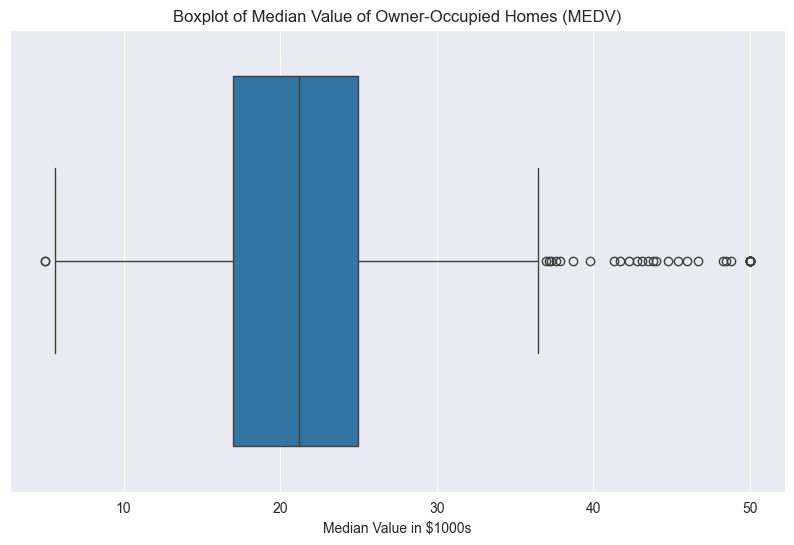

In [26]:
df = pd.read_csv('https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-ST0151EN-SkillsNetwork/labs/boston_housing.csv')
df.columns = df.columns.str.lower()

plt.figure(figsize=(10, 6))
sns.boxplot(x=df['medv'])
plt.title('Boxplot of Median Value of Owner-Occupied Homes (MEDV)')
plt.xlabel('Median Value in $1000s')
plt.show()

#### Add your code below following the instructions given in the course to complete the peer graded assignment


--- Task 1: Dataset Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 506 entries, 0 to 505
Data columns (total 14 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   unnamed: 0  506 non-null    int64  
 1   crim        506 non-null    float64
 2   zn          506 non-null    float64
 3   indus       506 non-null    float64
 4   chas        506 non-null    float64
 5   nox         506 non-null    float64
 6   rm          506 non-null    float64
 7   age         506 non-null    float64
 8   dis         506 non-null    float64
 9   rad         506 non-null    float64
 10  tax         506 non-null    float64
 11  ptratio     506 non-null    float64
 12  lstat       506 non-null    float64
 13  medv        506 non-null    float64
dtypes: float64(13), int64(1)
memory usage: 55.5 KB


--- Task 2: Generating Visualizations ---


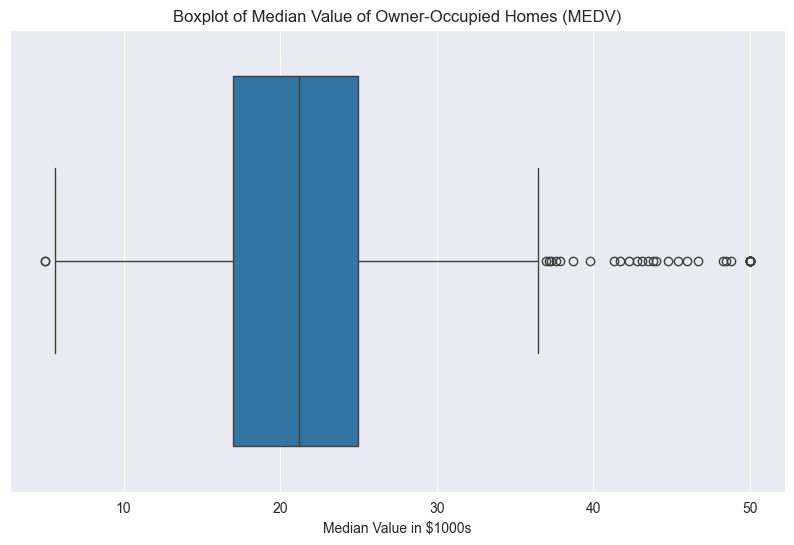

In [28]:
print("--- Task 1: Dataset Info ---")
df.info()
print("\n" + "="*50 + "\n")

print("--- Task 2: Generating Visualizations ---")

plt.figure(figsize=(10, 6))
sns.boxplot(x=df['medv'])
plt.title('Boxplot of Median Value of Owner-Occupied Homes (MEDV)')
plt.xlabel('Median Value in $1000s')
plt.show()

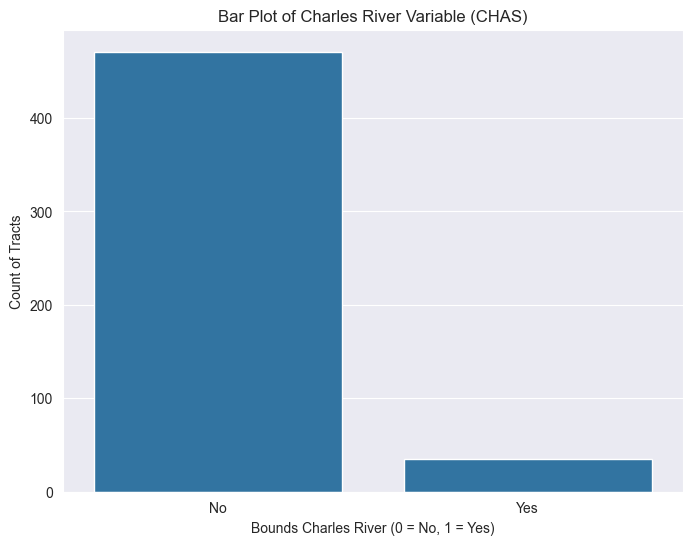

In [29]:
plt.figure(figsize=(8, 6))
sns.countplot(x=df['chas'])
plt.title('Bar Plot of Charles River Variable (CHAS)')
plt.xlabel('Bounds Charles River (0 = No, 1 = Yes)')
plt.ylabel('Count of Tracts')

plt.xticks(ticks=[0, 1], labels=['No', 'Yes'])
plt.show()

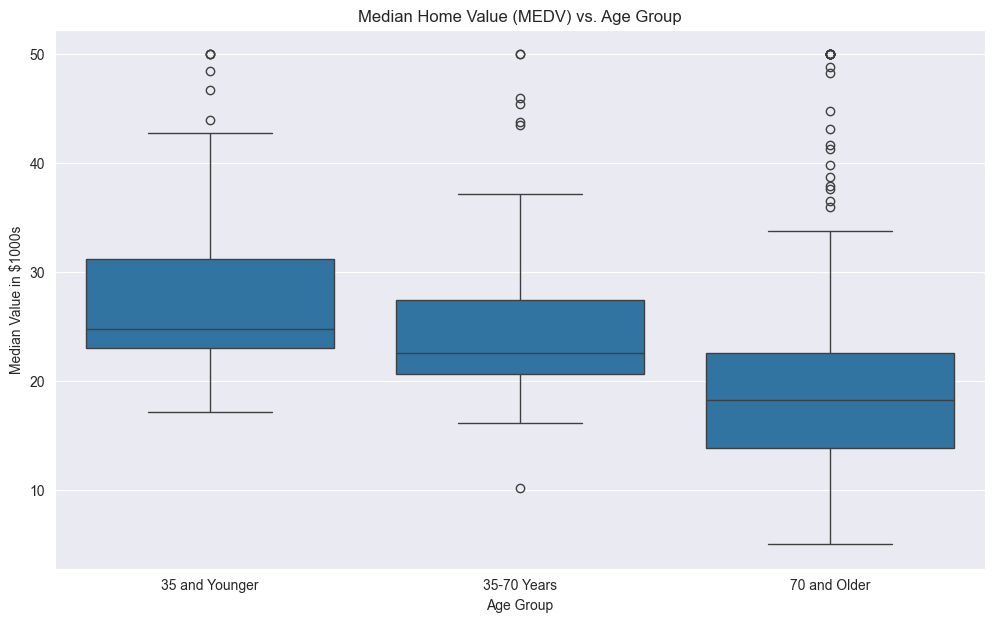

In [30]:
max_age = df['age'].max()
age_bins = [0, 35, 70, max_age]
age_labels = ['35 and Younger', '35-70 Years', '70 and Older']
df['age_group'] = pd.cut(df['age'], bins=age_bins, labels=age_labels, right=True, include_lowest=True)

plt.figure(figsize=(12, 7))
sns.boxplot(x='age_group', y='medv', data=df)
plt.title('Median Home Value (MEDV) vs. Age Group')
plt.xlabel('Age Group')
plt.ylabel('Median Value in $1000s')
plt.show()

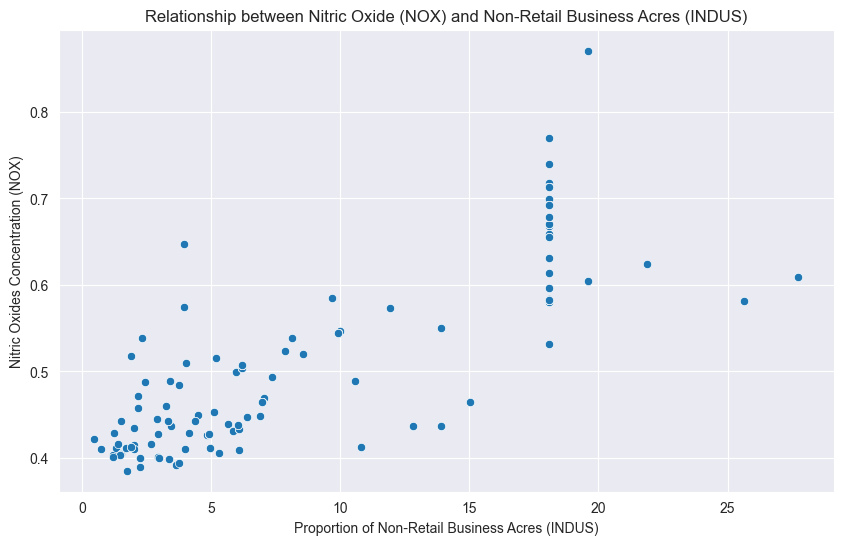

In [31]:
plt.figure(figsize=(10, 6))
sns.scatterplot(x='indus', y='nox', data=df)
plt.title('Relationship between Nitric Oxide (NOX) and Non-Retail Business Acres (INDUS)')
plt.xlabel('Proportion of Non-Retail Business Acres (INDUS)')
plt.ylabel('Nitric Oxides Concentration (NOX)')
plt.show()

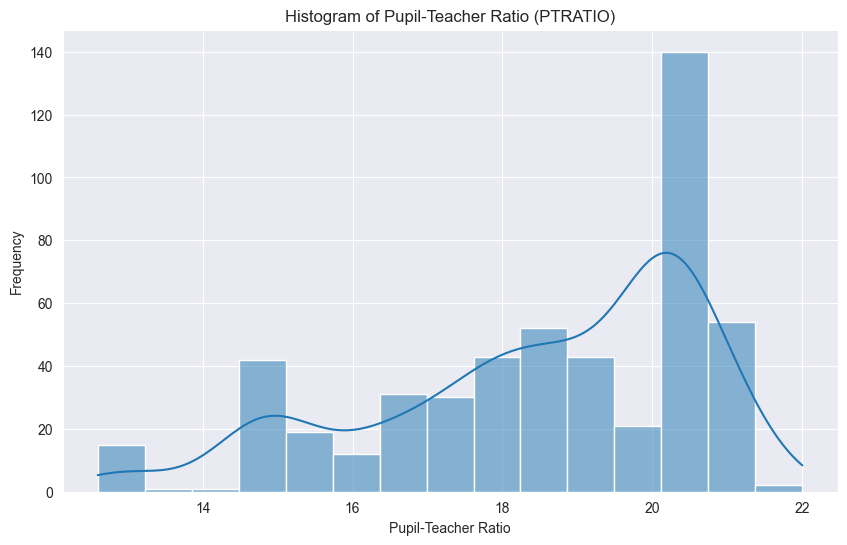

In [32]:
plt.figure(figsize=(10, 6))
sns.histplot(df['ptratio'], bins=15, kde=True)
plt.title('Histogram of Pupil-Teacher Ratio (PTRATIO)')
plt.xlabel('Pupil-Teacher Ratio')
plt.ylabel('Frequency')
plt.show()
print("\n" + "="*50 + "\n")

In [35]:
print("--- Task 3: Performing Hypothesis Tests (α = 0.05) ---")
alpha = 0.05

print("\n--- 3.1: T-test for MEDV vs CHAS ---")

print("Question: Is there a significant difference in median value of houses bounded by the Charles river or not?")
print("H₀ (Null): There is NO significant difference in the mean MEDV between houses bounding the river and those that do not.")
print("Hₐ (Alternative): There IS a significant difference in the mean MEDV between the two groups.\n")

chas_0 = df[df['chas'] == 0]['medv']
chas_1 = df[df['chas'] == 1]['medv']

levene_stat, levene_p = stats.levene(chas_0, chas_1)
print(f"Levene's Test: p-value = {levene_p:.4f}")
equal_var_bool = levene_p > alpha
if not equal_var_bool:
    print("Variances are unequal (p < 0.05). Using Welch's T-test.")
else:
    print("Variances are equal (p > 0.05). Using standard T-test.")

--- Task 3: Performing Hypothesis Tests (α = 0.05) ---

--- 3.1: T-test for MEDV vs CHAS ---
Question: Is there a significant difference in median value of houses bounded by the Charles river or not?
H₀ (Null): There is NO significant difference in the mean MEDV between houses bounding the river and those that do not.
Hₐ (Alternative): There IS a significant difference in the mean MEDV between the two groups.

Levene's Test: p-value = 0.0326
Variances are unequal (p < 0.05). Using Welch's T-test.


In [36]:
t_stat, p_value_ttest = stats.ttest_ind(chas_1, chas_0, equal_var=equal_var_bool)
print(f"\nTest Statistics:")
print(f"  T-Statistic: {t_stat:.4f}")
print(f"  P-value: {p_value_ttest:.4f}")

print("\nConclusion:")
if p_value_ttest < alpha:
    print(f"P-value ({p_value_ttest:.4f}) < {alpha}. We REJECT the null hypothesis (H₀).")
    print("There IS a statistically significant difference in median home values based on proximity to the Charles River.")
else:
    print(f"P-value ({p_value_ttest:.4f}) > {alpha}. We FAIL TO REJECT the null hypothesis (H₀).")
    print("There is NO statistically significant difference in median home values based on proximity to the Charles River.")


Test Statistics:
  T-Statistic: 3.1133
  P-value: 0.0036

Conclusion:
P-value (0.0036) < 0.05. We REJECT the null hypothesis (H₀).
There IS a statistically significant difference in median home values based on proximity to the Charles River.


In [37]:
print("\n--- 3.2: ANOVA for MEDV vs AGE Groups ---")
print("Question: Is there a difference in Median values of houses (MEDV) for each proportion of owner-occupied units built prior to 1940 (AGE)?")
print("H₀ (Null): The mean MEDV is the SAME for all three age groups.")
print("Hₐ (Alternative): At least one age group has a DIFFERENT mean MEDV.\n")

group_1 = df[df['age_group'] == '35 and Younger']['medv'].dropna()
group_2 = df[df['age_group'] == '35-70 Years']['medv'].dropna()
group_3 = df[df['age_group'] == '70 and Older']['medv'].dropna()

f_stat, p_value_anova = stats.f_oneway(group_1, group_2, group_3)
print("Test Statistics:")
print(f"  F-Statistic: {f_stat:.4f}")
print(f"  P-value: {p_value_anova:.4f}")

print("\nConclusion:")
if p_value_anova < alpha:
    print(f"P-value ({p_value_anova:.4f}) < {alpha}. We REJECT the null hypothesis (H₀).")
    print("There IS a statistically significant difference in median home values among the three age groups.")
else:
    print(f"P-value ({p_value_anova:.4f}) > {alpha}. We FAIL TO REJECT the null hypothesis (H₀).")
    print("There is NO statistically significant difference in median home values among the three age groups.")


--- 3.2: ANOVA for MEDV vs AGE Groups ---
Question: Is there a difference in Median values of houses (MEDV) for each proportion of owner-occupied units built prior to 1940 (AGE)?
H₀ (Null): The mean MEDV is the SAME for all three age groups.
Hₐ (Alternative): At least one age group has a DIFFERENT mean MEDV.

Test Statistics:
  F-Statistic: 36.4076
  P-value: 0.0000

Conclusion:
P-value (0.0000) < 0.05. We REJECT the null hypothesis (H₀).
There IS a statistically significant difference in median home values among the three age groups.


In [38]:
print("\n--- 3.3: Pearson Correlation for NOX vs INDUS ---")
print("Question: Can we conclude that there is no relationship between Nitric oxide concentrations and proportion of non-retail business acres per town?")
print("H₀ (Null): There is NO linear relationship between NOX and INDUS (Correlation = 0).")
print("Hₐ (Alternative): There IS a linear relationship between NOX and INDUS (Correlation ≠ 0).\n")

corr_coeff, p_value_corr = stats.pearsonr(df['nox'], df['indus'])
print("Test Statistics:")
print(f"  Pearson Correlation Coefficient (r): {corr_coeff:.4f}")
print(f"  P-value: {p_value_corr:.4f}")


print("\nConclusion:")
if p_value_corr < alpha:
    print(f"P-value ({p_value_corr:.4f}) < {alpha}. We REJECT the null hypothesis (H₀).")
    print(f"We CAN conclude that there IS a statistically significant linear relationship. (r = {corr_coeff:.4f})")
else:
    print(f"P-value ({p_value_corr:.4f}) > {alpha}. We FAIL TO REJECT the null hypothesis (H₀).")
    print("We CANNOT conclude that there is a relationship between NOX and INDUS.")

print("\n--- 3.4: Regression for MEDV vs DIS ---")
print("Question: What is the impact of an additional weighted distance to the five Boston employment centres on the median value of owner-occupied homes?")
print("H₀ (Null): The distance to employment centers (DIS) has NO impact on MEDV (Coefficient = 0).")
print("Hₐ (Alternative): The distance to employment centers (DIS) DOES have an impact on MEDV (Coefficient ≠ 0).\n")

Y = df['medv']
X = df['dis']
X = sm.add_constant(X)

model = sm.OLS(Y, X).fit()

print("Test Statistics (Regression Summary):")
print(model.summary())

dis_coeff = model.params['dis']
dis_pvalue = model.pvalues['dis']


--- 3.3: Pearson Correlation for NOX vs INDUS ---
Question: Can we conclude that there is no relationship between Nitric oxide concentrations and proportion of non-retail business acres per town?
H₀ (Null): There is NO linear relationship between NOX and INDUS (Correlation = 0).
Hₐ (Alternative): There IS a linear relationship between NOX and INDUS (Correlation ≠ 0).

Test Statistics:
  Pearson Correlation Coefficient (r): 0.7637
  P-value: 0.0000

Conclusion:
P-value (0.0000) < 0.05. We REJECT the null hypothesis (H₀).
We CAN conclude that there IS a statistically significant linear relationship. (r = 0.7637)

--- 3.4: Regression for MEDV vs DIS ---
Question: What is the impact of an additional weighted distance to the five Boston employment centres on the median value of owner-occupied homes?
H₀ (Null): The distance to employment centers (DIS) has NO impact on MEDV (Coefficient = 0).
Hₐ (Alternative): The distance to employment centers (DIS) DOES have an impact on MEDV (Coefficient 

In [39]:
print("\nConclusion:")
if dis_pvalue < alpha:
    print(f"P-value ({dis_pvalue:.4f}) < {alpha}. We REJECT the null hypothesis (H₀).")
    print("The weighted distance (DIS) IS a significant predictor of home value.")
    print(f"The coefficient for DIS is {dis_coeff:.4f}. This means that for each")
    print(f"additional unit of weighted distance from employment centers, the median")
    print(f"home value is predicted to INCREASE by ${dis_coeff*1000:.2f}.")
else:
    print(f"P-value ({dis_pvalue:.4f}) > {alpha}. We FAIL TO REJECT the null hypothesis (H₀).")
    print("The weighted distance (DIS) is NOT a significant predictor of home value.")

print("\n" + "="*50 + "\n--- All Tasks Complete ---")


Conclusion:
P-value (0.0000) < 0.05. We REJECT the null hypothesis (H₀).
The weighted distance (DIS) IS a significant predictor of home value.
The coefficient for DIS is 1.0916. This means that for each
additional unit of weighted distance from employment centers, the median
home value is predicted to INCREASE by $1091.61.

--- All Tasks Complete ---
